# Assignment 1 — Working with Open Data

In this assignment you take a **real, public dataset**, ask questions of it, answer them, and document your work so that someone else could reproduce it.

**A few things to know before you start:**
- This course is about **data, not code.** The point of A1 is the analytical questions and what the numbers tell you about how people behave — *not* whether you remember Python syntax.
- You can do the analysis **in Python here, or in Google Sheets.** Every question below works either way. Pick whatever lets you think about the data instead of fighting the tool.
- You may use an **AI assistant** (ChatGPT, Claude, …) to help you write code — with rules. See *A note on using AI* at the bottom before you do.

**What you'll turn in** (committed to your `hcde-410` repo):
1. This notebook, with your answers filled in.
2. A short **README.md** describing your work.
3. A **LICENSE** file, and a note about the dataset's own license.

Your commit history is part of the record — commit as you go.

## Part 0 — Get the data

The data comes from [data.seattle.gov](https://data.seattle.gov/), the City of Seattle's open-data portal. We'll use the [Burke-Gilman Trail counter north of NE 70th St](https://data.seattle.gov/Transportation/Burke-Gilman-Trail-north-of-NE-70th-St-Bicycle-and/2z5v-ecg8), which records **bike and pedestrian traffic, by hour, by direction**.

We'll pull the data straight from the city's API rather than downloading a file by hand. That's a small reproducibility win: anyone who runs this notebook gets the same data the same way, and it's written down exactly where it came from.

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# The dataset's API endpoint, and a query for one year of data (2019).
# You can paste the full URL into a browser to preview the raw data.
api_endpoint = "https://data.seattle.gov/resource/2z5v-ecg8.json?"
api_parameters = "$limit=50000&$where=date > '2019-01-01T00:00:00' AND date < '2020-01-01T00:00:00'"

response = requests.get(api_endpoint + api_parameters)
raw_data = response.json()
print("Downloaded", len(raw_data), "hourly records.")
# If this cell fails (e.g. the API is down), see the note below the next cell.

Downloaded 8759 hourly records.


Now load it into a **pandas DataFrame** — a table, like a spreadsheet you can compute with.

In [3]:
df = pd.DataFrame(raw_data)
df.head()

,date,bgt_north_of_ne_70th_total,ped_south,ped_north,bike_north,bike_south
0,2019-01-01T01:00:00.000,2,1,0,1,0
1,2019-01-01T02:00:00.000,1,0,0,0,1
2,2019-01-01T03:00:00.000,0,0,0,0,0
3,2019-01-01T04:00:00.000,1,0,0,1,0
4,2019-01-01T05:00:00.000,1,0,0,1,0


### Quick sanity checks

Whenever you work with data **you didn't create**, check that it means what you think before you analyze it. Two things need fixing here:
- the counts arrive as **text**, so we convert them to numbers;
- the `date` is a string, so we convert it to a real **datetime** and pull out the hour and weekday.

We'll also add tidy `bikes` and `peds` columns (north + south).

In [4]:
# convert the count columns from text to numbers
count_cols = ["bike_north", "bike_south", "ped_north", "ped_south", "bgt_north_of_ne_70th_total"]
df[count_cols] = df[count_cols].apply(pd.to_numeric, errors="coerce")

# convert the date string to a real datetime, and derive hour + weekday
df["date"] = pd.to_datetime(df["date"])
df["hour"] = df["date"].dt.hour
df["weekday"] = df["date"].dt.day_name()

# combined bike and pedestrian counts
df["bikes"] = df["bike_north"] + df["bike_south"]
df["peds"]  = df["ped_north"] + df["ped_south"]

df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8759 entries, 0 to 8758
Data columns (total 10 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   date                        8759 non-null   datetime64[ns]
 1   bgt_north_of_ne_70th_total  8759 non-null   int64         
 2   ped_south                   8759 non-null   int64         
 3   ped_north                   8759 non-null   int64         
 4   bike_north                  8759 non-null   int64         
 5   bike_south                  8759 non-null   int64         
 6   hour                        8759 non-null   int32         
 7   weekday                     8759 non-null   object        
 8   bikes                       8759 non-null   int64         
 9   peds                        8759 non-null   int64         
dtypes: datetime64[ns](1), int32(1), int64(7), object(1)
memory usage: 650.2+ KB


,date,bgt_north_of_ne_70th_total,ped_south,ped_north,bike_north,bike_south,hour,bikes,peds
count,8759,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000
mean,2019-07-02 12:00:00,58.423564,8.047380,8.363169,19.875671,22.137344,11.501313,42.013015,16.410549
min,2019-01-01 01:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2019-04-02 06:30:00,2.000000,0.000000,0.000000,0.000000,1.000000,6.000000,1.000000,0.000000
50%,2019-07-02 12:00:00,33.000000,5.000000,6.000000,9.000000,8.000000,12.000000,20.000000,11.000000
75%,2019-10-01 17:30:00,91.000000,13.000000,14.000000,31.000000,30.000000,17.500000,64.000000,27.000000
max,2019-12-31 23:00:00,1764.000000,1324.000000,782.000000,199.000000,961.000000,23.000000,1039.000000,1752.000000
std,NaN,73.656910,16.882468,13.164217,26.299728,34.080707,6.921886,56.534598,27.675776


**Look at what `describe()` tells you.** Are there hours with 0 traffic? Any missing values (a sensor can go offline)? Note anything odd — you'll want to mention data limitations later.

**No-code option:** run the next cell to save the cleaned data as a CSV, then open it in Google Sheets and do your analysis there. If you go this route, title your sheet **"A1 — [your name]"**, share it so anyone with the link can view, and paste the link into your written answers.

In [5]:
df.to_csv("bg_hourly_2019.csv", index=False)
print("Saved bg_hourly_2019.csv — a row per hour of 2019.")

Saved bg_hourly_2019.csv — a row per hour of 2019.


## Part 1 — One worked example: when do cyclists ride?

Here is the whole technique, **once**, so you can see the pattern. After this, the questions are yours.

The move is always the same: **group → summarize → plot → interpret.** In pandas that's a couple of lines (no loops needed).

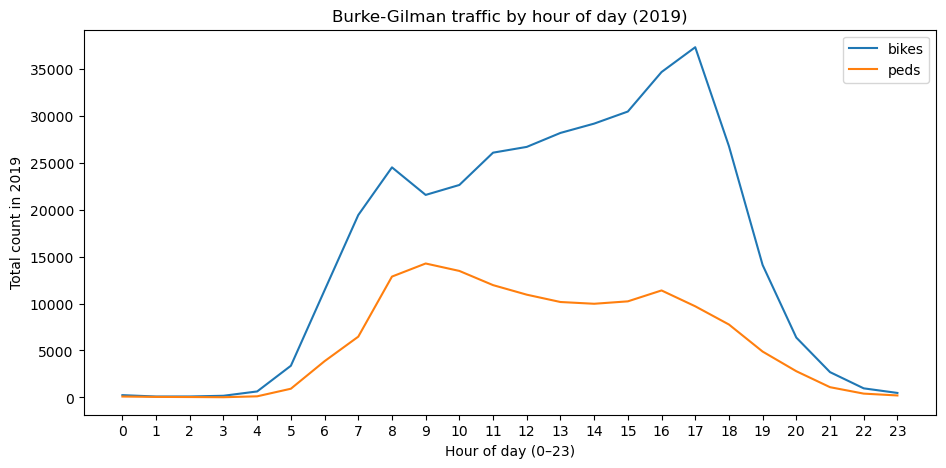

In [6]:
# group every row by its hour of day, and sum bikes and peds within each hour
by_hour = df.groupby("hour")[["bikes", "peds"]].sum()

by_hour.plot(figsize=(11, 5))
plt.title("Burke-Gilman traffic by hour of day (2019)")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Total count in 2019")
plt.xticks(range(0, 24))
plt.show()

**Now read the plot — this is the actual work.** What does the shape tell you? Do you see one peak or two? What might a double peak mean about *why* people are on the trail? That interpretation — turning a shape into a claim about human behavior — is what every question below is really asking for.

## Part 2 — Your analysis

Answer each question below. For every one:
1. **Show how you got there** — a pandas cell here, or (no-code) a link to your Google Sheet in the answer.
2. **Interpret it in 2–4 sentences** — what does this say about how people actually use the trail? The interpretation is the point, not the number.

There isn't a single right answer to most of these. Making a reasonable choice and *defending* it is the skill.

**Q1. When is the trail busiest, and when is it quietest?**
Decide what *busy* means to you first — a single hour? a stretch of the day? bikes and peds together, or separately? — and say why you chose that.

Busiest hour: 17 -> 128.8
Quietest hour: 2 -> 0.4
hour
0       0.9
1       0.4
2       0.4
3       0.6
4       2.1
5      11.8
6      41.8
7      70.9
8     102.4
9      98.2
10     98.9
11    104.2
12    103.1
13    105.0
14    107.2
15    111.4
16    126.1
17    128.8
18     94.6
19     52.0
20     25.1
21     10.4
22      3.8
23      1.9
Name: total, dtype: float64


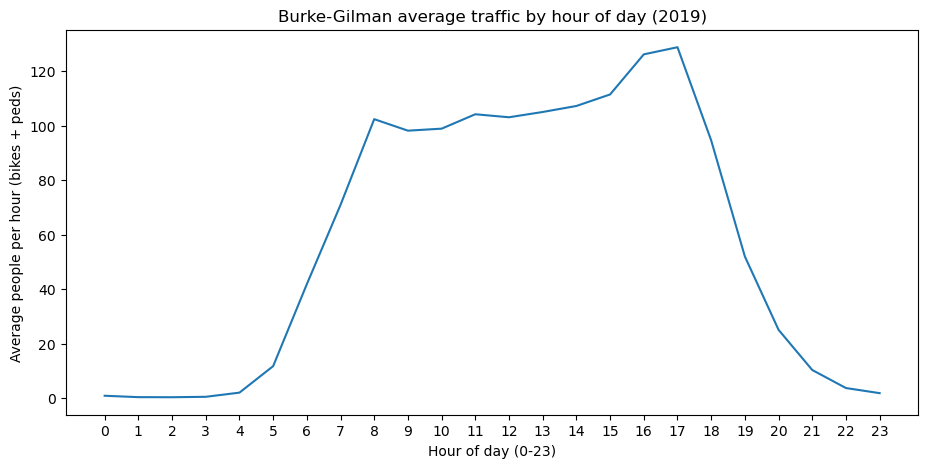

In [7]:
# Your code for Q1 (or put a Google Sheets link in your written answer below)
# average bikes and peds for each hour of day, then combine them
by_hour = df.groupby("hour")[["bikes", "peds"]].mean()
by_hour["total"] = by_hour["bikes"] + by_hour["peds"]

# print the busiest and quietest hours so my written answer uses real numbers
print("Busiest hour:", by_hour["total"].idxmax(), "->", round(by_hour["total"].max(), 1))
print("Quietest hour:", by_hour["total"].idxmin(), "->", round(by_hour["total"].min(), 1))

# look at every hour, to check whether midnight to 2 AM are all similarly low
print(by_hour["total"].round(1))

# plot the combined average
by_hour["total"].plot(figsize=(11, 5))
plt.title("Burke-Gilman average traffic by hour of day (2019)")
plt.xlabel("Hour of day (0-23)")
plt.ylabel("Average people per hour (bikes + peds)")
plt.xticks(range(0, 24))
plt.show()

**Your Q1 answer:**

I defined “busy” as the hour of the day with the highest average combined bike and pedestrian count. I used the average rather than the total because if the sensor was offline for some hours, .sum() would treat those as zero and drag an hour down, while .mean() skips missing values. Using the average across all days in 2019, the trail is busiest at 5 PM (hour 17) with about 128.8 people per hour, and quietest from 1-2 AM with about 0.4 people per hour. The 5 PM peak likely reflects people heading home from work or class, along with some evening errands and recreation. The trail is quietest from 1-2 AM, when most people are asleep, which makes sense. This combined view can’t tell me why people are there, so the commuting explanation is an inference I test more directly in Q3.

**Q2. Do cyclists and pedestrians use the trail at different times of day?**
Compare their hourly patterns. If they differ, what might explain it?

Bike peak hour: 17 -> 102.2
Ped peak hour: 9 -> 39.1


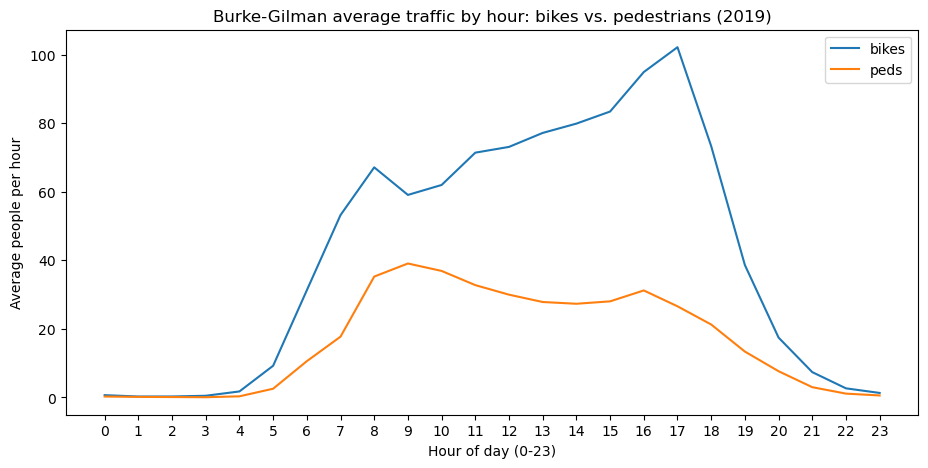

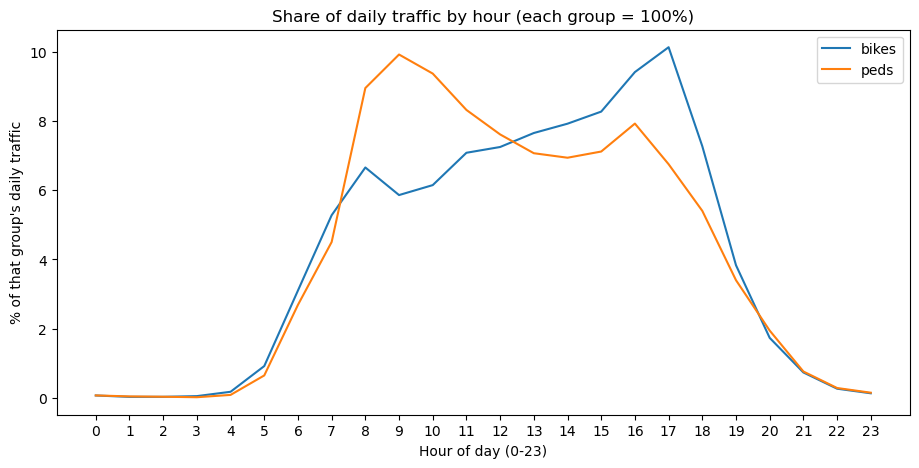

In [8]:
# Your code for Q2
# average bikes and peds for each hour of day (kept separate this time)
by_hour = df.groupby("hour")[["bikes", "peds"]].mean()

# peak hour for each group
print("Bike peak hour:", by_hour["bikes"].idxmax(), "->", round(by_hour["bikes"].max(), 1))
print("Ped peak hour:", by_hour["peds"].idxmax(), "->", round(by_hour["peds"].max(), 1))

# plot 1: average counts, side by side
by_hour.plot(figsize=(11, 5))
plt.title("Burke-Gilman average traffic by hour: bikes vs. pedestrians (2019)")
plt.xlabel("Hour of day (0-23)")
plt.ylabel("Average people per hour")
plt.xticks(range(0, 24))
plt.show()

# plot 2: each group's share of its own daily traffic, to compare shapes
share = by_hour / by_hour.sum() * 100
share.plot(figsize=(11, 5))
plt.title("Share of daily traffic by hour (each group = 100%)")
plt.xlabel("Hour of day (0-23)")
plt.ylabel("% of that group's daily traffic")
plt.xticks(range(0, 24))
plt.show()


**Your Q2 answer:**

Cyclists and pedestrians use the trail at different times. Pedestrian traffic peaks in the morning at about 9am and tapers off through the day, while bike traffic builds gradually and peaks in the evening at 5pm. I infer that there is a peak in pedestrian traffic at 9am as people are walking to class, work, or maybe even walking their dog. The reason why cyclists traffic peak at 5pm may be cyclists getting some exercise after work and have more time to go a further distance via bike ride. This is an inference, since the counter can’t tell me why people are on the trail.

**Q3. Commuting or recreation?**
Is there evidence people use the Burke-Gilman to *commute*, not just for fun? Compare **weekdays vs. weekends** (we made a `weekday` column for you), and maybe morning vs. evening. Define what a "commuting pattern" would look like in the data, then say whether you see it.

*Hint: `df.groupby("weekday")[["bikes","peds"]].sum()` gets you started. Weekends and weekdays will look different if commuting is real.*

          bikes  peds
day_type             
Weekday    37.5  14.1
Weekend    53.3  22.1


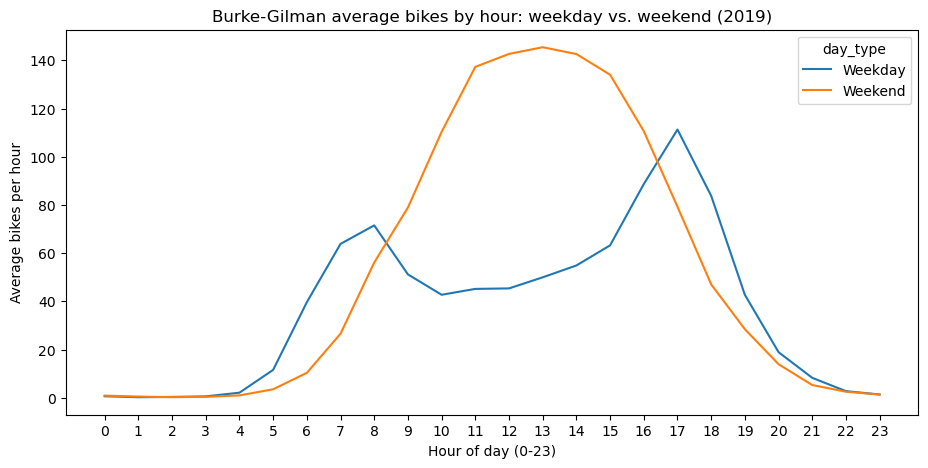

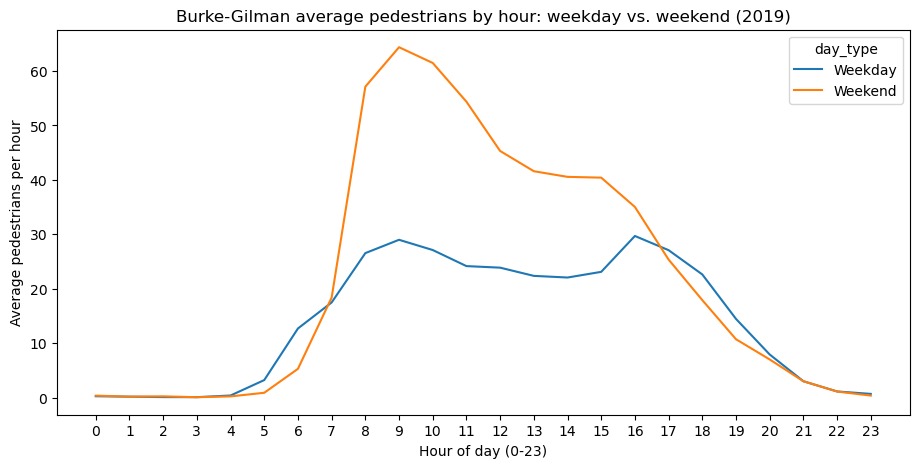

In [10]:
# Your code for Q3
# label each row as weekday or weekend
df["day_type"] = df["weekday"].isin(["Saturday", "Sunday"]).map({True: "Weekend", False: "Weekday"})

# 1. average hourly traffic: weekday vs. weekend (per-hour averages, so the
#    5 weekdays and 2 weekend days are comparable)
print(df.groupby("day_type")[["bikes", "peds"]].mean().round(1))

# 2. average count by hour of day, split by day type
by_hour_type = df.groupby(["day_type", "hour"])[["bikes", "peds"]].mean()

# 3. plot bikes and peds, weekday vs. weekend
for col, label in [("bikes", "Bikes"), ("peds", "Pedestrians")]:
    by_hour_type[col].unstack(level=0).plot(figsize=(11, 5))
    plt.title(f"Burke-Gilman average {label.lower()} by hour: weekday vs. weekend (2019)")
    plt.xlabel("Hour of day (0-23)")
    plt.ylabel(f"Average {label.lower()} per hour")
    plt.xticks(range(0, 24))
    plt.show()

**Your Q3 answer:**

I defined a commuting pattern as two sharp peaks on weekdays, one in the morning and one in the evening rush, that flatten into a single midday hump on weekends. For cyclists, the data shows this pattern clearly. On weekdays, bike traffic peaks at about 72 per hour at 8 AM and about 111 at 5 PM, with a dip to roughly 43 in between. On weekends, that double peak disappears and bikes instead form one broad hump peaking around 145 per hour near 1 PM. This suggests many weekday cyclists are commuting, while weekend riders are mostly out for recreation.

Pedestrians show a much weaker commuting signal. Weekday pedestrian traffic is low and fairly flat, with small bumps around 9 AM and 4 PM (roughly 29 and 30 people per hour). On weekends it is higher, peaking around 64 per hour at 9 AM, so walkers appear to use the trail more for leisure or exercise than for getting to work. Overall, the trail serves both purposes: commuting is real, especially for bikes, but weekend recreation brings the highest traffic. This is an inference, since the counter can’t tell me why people are on the trail, and holidays and weekend work shifts blur the weekday/weekend split.

**Q4. Direction and flow.**
The counter records **north vs. south** separately. Are mornings mostly one direction and evenings the other? What would that tell you about who's using the trail and where they're heading?

Weekday MORNING (6-9 AM) average per hour:
bike_north    40.2
bike_south    16.3
ped_north     11.6
ped_south      9.8
dtype: float64

Weekday EVENING (4-7 PM) average per hour:
bike_north    25.6
bike_south    56.0
ped_north     11.3
ped_south     12.1
dtype: float64


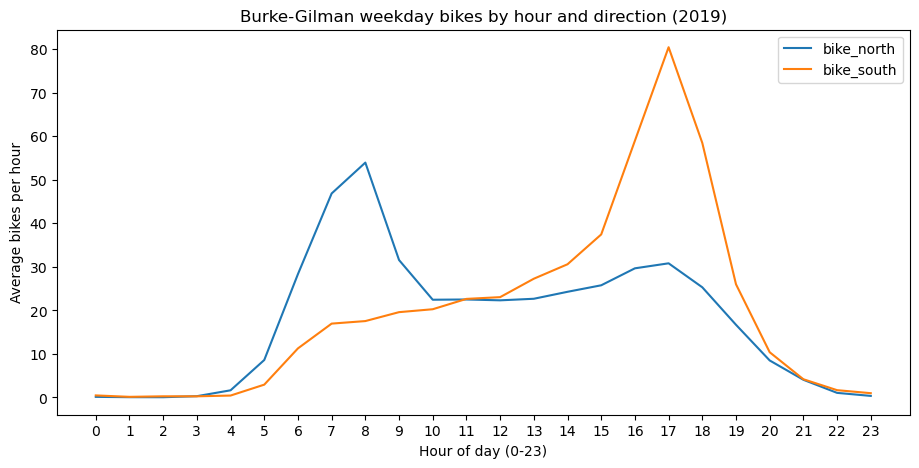

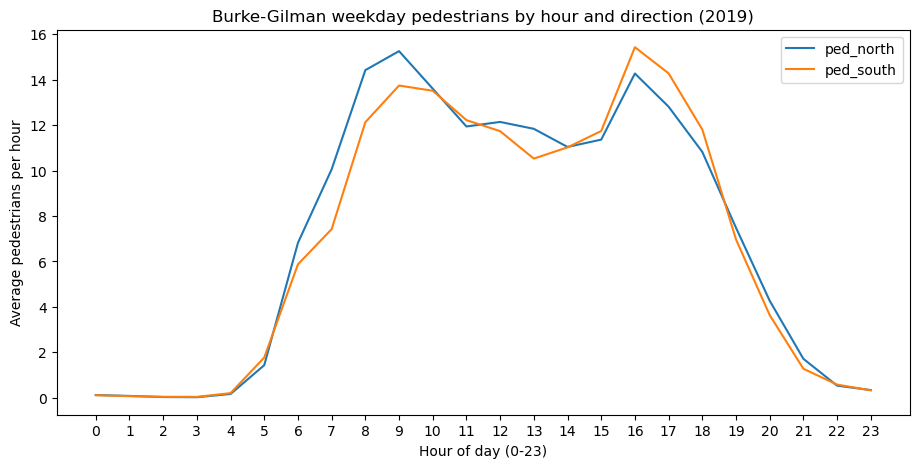

In [12]:
# Your code for Q4
# make sure the weekday/weekend label exists (same as Q3)
df["day_type"] = df["weekday"].isin(["Saturday", "Sunday"]).map({True: "Weekend", False: "Weekday"})

dir_cols = ["bike_north", "bike_south", "ped_north", "ped_south"]

# 1. average count by hour and direction, weekdays only
weekday = df[df["day_type"] == "Weekday"]
by_hour_dir = weekday.groupby("hour")[dir_cols].mean()

# 2. compare morning (6-9 AM) vs. evening (4-7 PM) by direction
morning = by_hour_dir.loc[6:9].mean().round(1)
evening = by_hour_dir.loc[16:19].mean().round(1)
print("Weekday MORNING (6-9 AM) average per hour:")
print(morning)
print("\nWeekday EVENING (4-7 PM) average per hour:")
print(evening)

# 3. plot north vs. south for bikes and for peds
for mode, label in [("bike", "Bikes"), ("ped", "Pedestrians")]:
    by_hour_dir[[f"{mode}_north", f"{mode}_south"]].plot(figsize=(11, 5))
    plt.title(f"Burke-Gilman weekday {label.lower()} by hour and direction (2019)")
    plt.xlabel("Hour of day (0-23)")
    plt.ylabel(f"Average {label.lower()} per hour")
    plt.xticks(range(0, 24))
    plt.show()

**Your Q4 answer:**

The direction data shows a strong tidal flow for cyclists. On weekday mornings (6-9 AM), bikes heading north average about 40 per hour versus about 16 heading south, roughly 2.5 times as many. In the evening (4-7 PM) it reverses: bikes heading south average about 56 per hour versus about 26 heading north, roughly 2.2 times as many. The sharpest peaks match the commuting hours from Q3, with northbound bikes peaking around 8 AM and southbound bikes around 5 PM. This suggests many cyclists are commuting: riding north in the morning and returning south in the evening. That fits a trail where many riders live north of the counter and travel toward the UW or downtown for work or class, though the counter can’t tell me where anyone’s trip began or ended.

Pedestrians show almost no directional pattern. Morning and evening averages are close in both directions (about 12 north vs. 10 south in the morning, and 11 vs. 12 in the evening), and the two lines nearly overlap on the chart. That suggests walkers mostly make short, round-trip outings, like a walk or run that goes out and back past the counter, rather than a one-way commute. So the direction data supports commuting for cyclists but doesn’t point to it for pedestrians.

## Part 3 — Make it reproducible

Good data work can be picked up and re-run by someone else. Two short deliverables:

**1. A `README.md`** in your `A1` folder. Use this template:

```
# A1 — Working with Open Data

**Dataset:** Burke-Gilman Trail counter north of NE 70th St
**Source:** https://data.seattle.gov/Transportation/.../2z5v-ecg8  (pulled YYYY-MM-DD)
**License / terms of use:** <find it on the dataset's page and note it here>

## Questions I asked
- ...

## How to re-run
Open `A1.ipynb` and run all cells (needs `requests`, `pandas`, `matplotlib`).
```

**2. A `LICENSE`** — keep the license file in this folder, and in your README **note the dataset's own license or terms of use** (open datasets almost always have one; find it on the dataset's page). Using open data responsibly means knowing what you're allowed to do with it — that's part of the assignment, not an afterthought.

### One more thing: read the data critically

In 3–4 sentences, name **one limitation or bias** in this dataset and how it could mislead someone who trusted it uncritically.

*(A sensor counts bodies, not intentions. It's one location on a long trail. Some hours may be missing when the counter was offline. A tandem bike counts once. What else?)* This is a warm-up for A2, where finding bias in data is the whole assignment.

**Your answer:**

This dataset has gaps and possible sensor errors, and an average that ignores them can mislead. (In the full dataset, the pedestrian columns are empty for a large share of hours, and some maximum values (4,095 and 8,191) look more like recording glitches than real counts.) If someone trusted these numbers uncritically, a few bad readings could shift a “busiest hour” or inflate an average, and missing hours could make the trail look quieter than it really was. A sensor also counts bodies at one spot, not trips, so it can’t tell commuters from recreational riders or show who is missing from the trail entirely.

## Optional — going further

If you want to push further (not required for full credit):
- Which **day of the week** is busiest? Is it the same for bikes and pedestrians?
- Has the trail gotten **busier over time**? (the data goes back to 2014 — change the year in the query)
- Do fewer people ride when it's **cold or wet**? (join with a Seattle [weather dataset](https://data.seattle.gov/))
- Compare with another counter — the [Fremont Bridge](https://data.seattle.gov/Transportation/Fremont-Bridge-Bicycle-Counter/65db-xm6k) or the [MTS Trail](https://data.seattle.gov/Transportation/MTS-Trail-west-of-I-90-Bridge-Bicycle-and-Pedestri/u38e-ybnc).

## A note on using AI

You may use an LLM (ChatGPT, Claude, …) to help you write code or make a plot. Treat it as a **tool you supervise, not an author you trust**:
- paste the **prompt** you used into a Markdown cell,
- **run** the output and check it against what you expected,
- note **what you changed and why**.

Here, AI is your assistant. In **A3** it becomes your subject of study. Code that runs but that you can't explain won't earn credit — the point is that *you* can ask a question of data and defend the answer.

## AI Use
I used ClaudeAI to help me write and check my code to ensure the data set is correct and working. I also utilized it to break down and questions
and instructions I had trouble understanding.

Example Prompts Used:
- does this response make sense?
- does 24000 people per hour make sense for x?
- is this an accurate way to define when the busiest time is?
- I'm not quite sure what it's asking of me here.